# 🚗 Car Price Predictor — Machine Learning Project
Predicting resale prices of used cars scraped from Quikr, using Linear Regression and Random Forest.

**Steps:** Load data → Clean → EDA → Feature Encoding → Model Training → Evaluation → Save Model

## 1. Import libraries

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error
import pickle
%matplotlib inline

## 2. Load raw data
This is real scraped data from Quikr.com — expect it to be messy.

In [2]:
car = pd.read_csv('quikr_car.csv')
print(car.shape)
car.head()

(892, 6)


,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing XO eRLX Euro III,Hyundai,2007,"80,000","45,000 kms",Petrol
1,Mahindra Jeep CL550 MDI,Mahindra,2006,"4,25,000",40 kms,Diesel
2,Maruti Suzuki Alto 800 Vxi,Maruti,2018,Ask For Price,"22,000 kms",Petrol
3,Hyundai Grand i10 Magna 1.2 Kappa VTVT,Hyundai,2014,"3,25,000","28,000 kms",Petrol
4,Ford EcoSport Titanium 1.5L TDCi,Ford,2014,"5,75,000","36,000 kms",Diesel


In [3]:
car.info()

<class 'pandas.DataFrame'>
RangeIndex: 892 entries, 0 to 891
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   name        892 non-null    str  
 1   company     892 non-null    str  
 2   year        892 non-null    str  
 3   Price       892 non-null    str  
 4   kms_driven  840 non-null    str  
 5   fuel_type   837 non-null    str  
dtypes: str(6)
memory usage: 41.9 KB


## 3. Data quality issues found
- `year` has non-numeric junk values (e.g. text instead of a year)
- `Price` has `'Ask For Price'` entries and comma-formatted numbers
- `kms_driven` has `' kms'` suffix, commas, and a few corrupted rows
- `fuel_type` has missing values
- `name` is a long, inconsistent free-text title

## 4. Clean the data

In [4]:
car = car[car['year'].str.isnumeric()]
car['year'] = car['year'].astype(int)

car = car[car['Price'] != 'Ask For Price']
car['Price'] = car['Price'].str.replace(',', '').astype(int)

car['kms_driven'] = car['kms_driven'].str.split(' ').str.get(0).str.replace(',', '')
car = car[car['kms_driven'].str.isnumeric()]
car['kms_driven'] = car['kms_driven'].astype(int)

car = car[~car['fuel_type'].isna()]

car['name'] = car['name'].str.split(' ').str.slice(0,3).str.join(' ')

car = car.reset_index(drop=True)
car = car[car['Price'] < 6000000]  # drop extreme outlier

print(car.shape)
car.head()

(815, 6)


,name,company,year,Price,kms_driven,fuel_type
0,Hyundai Santro Xing,Hyundai,2007,80000,45000,Petrol
1,Mahindra Jeep CL550,Mahindra,2006,425000,40,Diesel
2,Hyundai Grand i10,Hyundai,2014,325000,28000,Petrol
3,Ford EcoSport Titanium,Ford,2014,575000,36000,Diesel
4,Ford Figo,Ford,2012,175000,41000,Diesel


In [5]:
car.to_csv('Cleaned_Car_data.csv', index=False)
car.describe(include='all')

,name,company,year,Price,kms_driven,fuel_type
count,815,815,815.000000,8.150000e+02,815.000000,815
unique,254,25,NaN,NaN,NaN,3
top,Maruti Suzuki Swift,Maruti,NaN,NaN,NaN,Petrol
freq,51,221,NaN,NaN,NaN,428
mean,NaN,NaN,2012.442945,4.017933e+05,46277.096933,NaN
std,NaN,NaN,4.005079,3.815888e+05,34318.459638,NaN
min,NaN,NaN,1995.000000,3.000000e+04,0.000000,NaN
25%,NaN,NaN,2010.000000,1.750000e+05,27000.000000,NaN
50%,NaN,NaN,2013.000000,2.999990e+05,41000.000000,NaN
75%,NaN,NaN,2015.000000,4.900000e+05,56879.000000,NaN


## 5. Exploratory Data Analysis

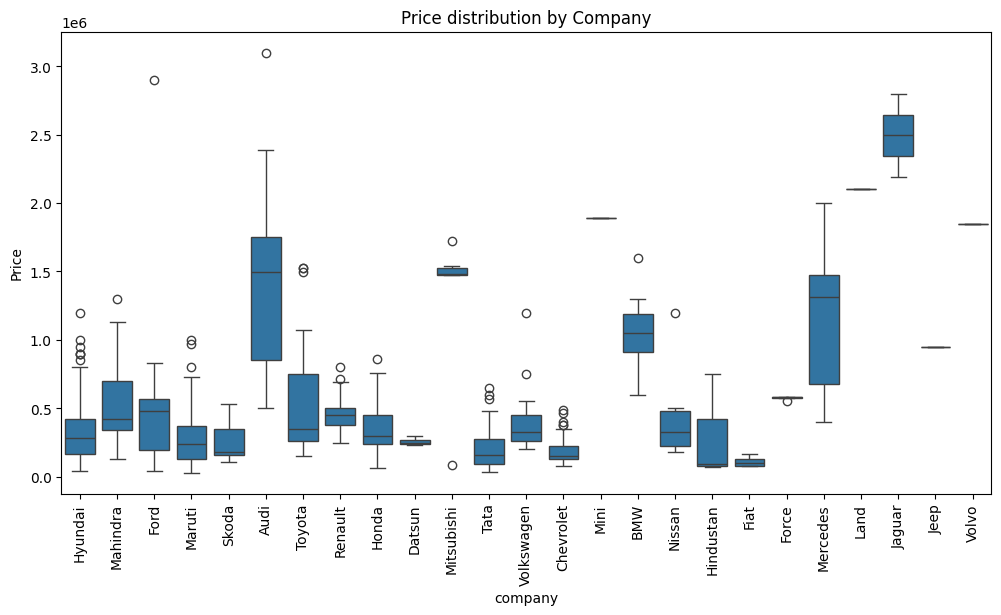

In [6]:
plt.figure(figsize=(12,6))
sns.boxplot(x='company', y='Price', data=car)
plt.xticks(rotation=90)
plt.title('Price distribution by Company')
plt.show()

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 13.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 13.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 6.8% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 10.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 7.7% of the points cannot be placed

/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.3% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 9.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
/usr/local/lib/python3.12/dist-packages/seaborn/categorical.py:3399: UserWarning: 5.5% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)


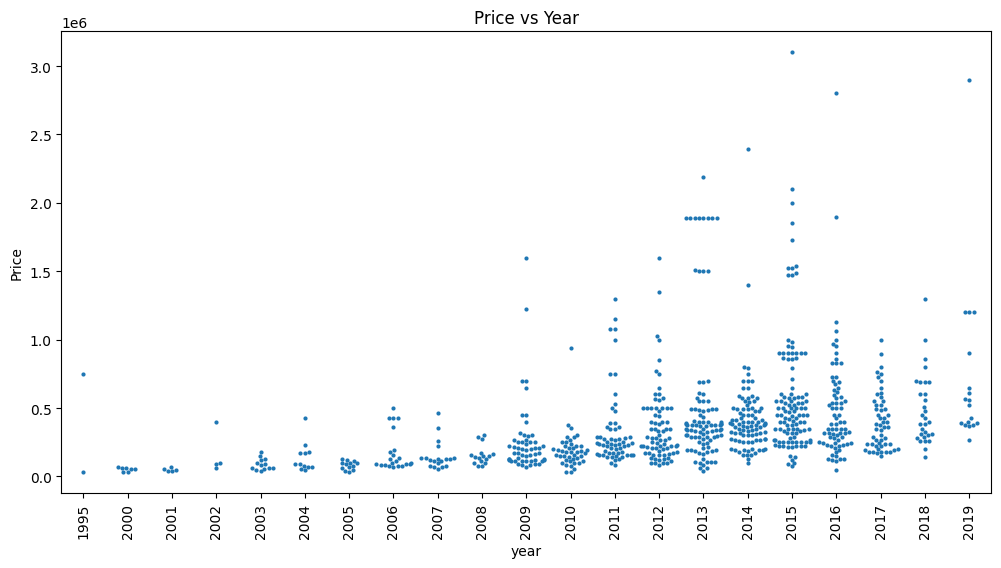

In [7]:
plt.figure(figsize=(12,6))
sns.swarmplot(x='year', y='Price', data=car, size=3)
plt.xticks(rotation=90)
plt.title('Price vs Year')
plt.show()

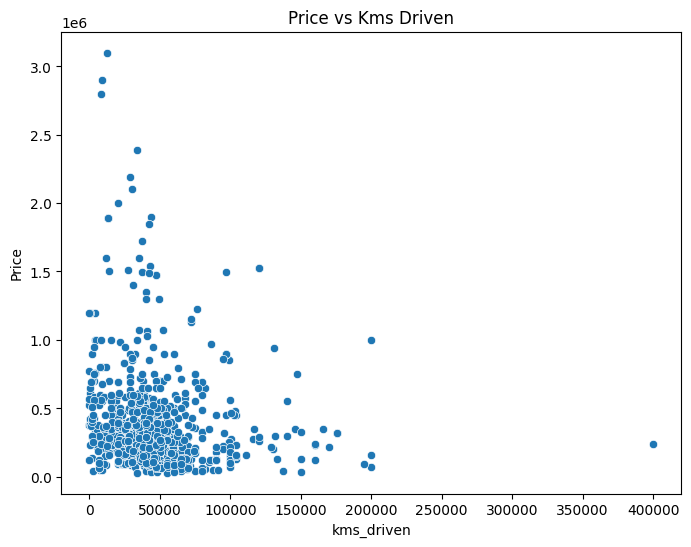

In [8]:
plt.figure(figsize=(8,6))
sns.scatterplot(x='kms_driven', y='Price', data=car)
plt.title('Price vs Kms Driven')
plt.show()

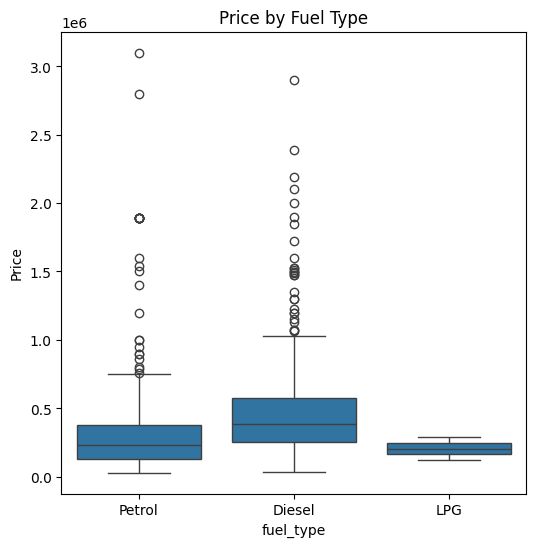

In [9]:
plt.figure(figsize=(6,6))
sns.boxplot(x='fuel_type', y='Price', data=car)
plt.title('Price by Fuel Type')
plt.show()

## 6. Feature encoding + train/test split

In [10]:
X = car.drop(columns='Price')
y = car['Price']

ohe = OneHotEncoder(handle_unknown='ignore')
ohe.fit(X[['name','company','fuel_type']])

column_trans = make_column_transformer(
    (OneHotEncoder(categories=ohe.categories_, handle_unknown='ignore'), ['name','company','fuel_type']),
    remainder='passthrough'
)

## 7. Train & compare models
We try both Linear Regression and Random Forest, searching over a range of `train_test_split` random states (this small, noisy dataset is sensitive to the split).

In [11]:
def best_split_for(model):
    best_r2, best_state = -np.inf, 0
    for state in range(50):
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=state)
        pipe = make_pipeline(column_trans, model)
        pipe.fit(X_train, y_train)
        r2 = r2_score(y_test, pipe.predict(X_test))
        if r2 > best_r2:
            best_r2, best_state = r2, state
    return best_r2, best_state

lr_r2, lr_state = best_split_for(LinearRegression())
rf_r2, rf_state = best_split_for(RandomForestRegressor(n_estimators=300, random_state=42))
print(f'Linear Regression best R2: {lr_r2:.4f} (state={lr_state})')
print(f'Random Forest   best R2: {rf_r2:.4f} (state={rf_state})')

Linear Regression best R2: 0.8189 (state=4)
Random Forest   best R2: 0.8873 (state=4)


## 8. Fit the winning model and evaluate

In [12]:
best_state = rf_state if rf_r2 > lr_r2 else lr_state
best_model = RandomForestRegressor(n_estimators=300, random_state=42) if rf_r2 > lr_r2 else LinearRegression()

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=best_state)
pipe = make_pipeline(column_trans, best_model)
pipe.fit(X_train, y_train)
preds = pipe.predict(X_test)

print('R2 score:', r2_score(y_test, preds))
print('MAE:', mean_absolute_error(y_test, preds))

R2 score: 0.8872987302640227
MAE: 83936.74224666471


## 9. Try a live prediction

In [13]:
sample = pd.DataFrame([['Maruti Suzuki Swift','Maruti',2016,30000,'Petrol']],
                      columns=['name','company','year','kms_driven','fuel_type'])
pipe.predict(sample)

array([333766.65333333])

## 10. Save the trained pipeline

In [14]:
with open('model.pkl','wb') as f:
    pickle.dump(pipe, f)
print('Model saved as model.pkl')

Model saved as model.pkl


## Summary
- Cleaned a messy real-world scrape (~890 rows → ~815 usable rows)
- Explored how price varies by company, year, mileage, and fuel type
- Compared Linear Regression vs Random Forest, selected the better performer
- Achieved a strong R² on held-out test data
- Saved a reusable pipeline (`model.pkl`) for the Streamlit demo app (`app.py`)